# 02 | Transformer forecasting: model evaluation

**Applied Computing — CO₂ concentration forecasting**

This notebook evaluates a custom Transformer using seven-experiment development cross-validation and the reserved test experiment `140207_1.xlsx`. It compares training objectives, history lengths, forecast horizons, convergence, and performance relative to persistence. Analyses use saved predictions; no model retraining occurs. A companion notebook investigates the error mechanisms identified here.

**Evaluation scope.** Primary scores use genuinely measured L2–L6 targets; L1 analyzer readings are unreliable, and reconstructed training targets are excluded from observed-only scoring. The combined-input model assumes retrospective availability of analyzer-location labels, so operational real-time performance has not been established.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

# Works when launched from either the project root or notebooks/.
CANDIDATES = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path('/mnt/data/nb2_validation')]
ROOT = next((p for p in CANDIDATES if (p/'results'/'earlystop_cv'/'cv_summary.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Expected results/earlystop_cv/cv_summary.csv under the project root. Set ROOT manually.')
R = ROOT/'results'/'earlystop_cv'
summary = pd.read_csv(R/'cv_summary.csv')
folds = pd.read_csv(R/'cv_folds.csv')
pred = pd.read_csv(R/'outer_predictions.csv')
inner = pd.read_csv(R/'inner_epoch_metrics.csv')
stops = pd.read_csv(R/'early_stopping_summary.csv')
scales = pd.read_csv(R/'objective_scale_comparison.csv')
selected = json.loads((R/'selected_config.json').read_text())
LOSS_NAMES = {'raw':'Raw Huber', 'variance':'Variance-scaled', 'noise':'Noise-aware'}
print('Archive:', R)
print('Configurations:', len(summary), '| prediction rows:', len(pred), '| inner epoch rows:', len(inner))
assert len(summary)==12, 'Expected 12 configurations'
assert not (pred.experiment.astype(str).str.contains('140207_1')).any(), 'Reserved test run found in development predictions'


Archive: /Users/niharikadeshpande/Downloads/co2_transformer_submission/results/earlystop_cv
Configurations: 12 | prediction rows: 48096 | inner epoch rows: 43780


## 1. Experimental design and evaluation protocol

A custom Transformer maps historical process measurements and CO₂-history information to six concentration forecasts. The three training objectives apply different error scaling within the Huber loss. Reconstructed targets contribute to training with reduced weight (0.05), but not to observed-only evaluation.

Each of the seven development experiments is held out in turn. Inner validation determines early stopping without using the outer held-out experiment. Model configuration is selected by the macro-average of outer-fold observed MAE. Because these same folds inform configuration selection, the winning score is a **development selection statistic**, not an unbiased post-selection performance estimate. The reserved experiment provides the final test.

**Comparability.** Persistence comparisons use matched eligible targets with finite observations and forecasts. Macro scores weight experiments equally; pooled scores weight eligible forecast records equally. Forecast records within an experiment are temporally dependent, so the reported differences are descriptive rather than formal independent-replicate significance tests.

### Implemented forecasting architecture

The architecture below was verified against `src/co2_submission/model.py` and `transformer.py` in the supplied release archive. It describes the **combined-input** configuration evaluated here, rather than a generic Transformer.

| Component | Implemented specification |
|:--|:--|
| Historical input | 54 channels per step: 30 process measurements and 24 CO₂-history/availability channels |
| Input projection | Linear mapping from 54 to 32 dimensions |
| Temporal representation | Sinusoidal positional encoding |
| Encoder | Two custom pre-normalized residual encoder blocks |
| Attention | Four heads, eight dimensions per head; learned Q/K/V projections, scaled dot-product attention, and a triangular causal mask |
| Feed-forward sublayer | 32 → 64 → 32, GELU activation |
| Regularization | Dropout probability 0.10; layer normalization |
| Forecast readout | Final historical token; 32 → 32 → 6 prediction head |
| Output constraint | Softplus, ensuring non-negative concentrations at all six locations |
| Output calibration | Training-only location means and scales; final head initialized to zero, giving training-mean initial predictions |

The six outputs are produced jointly; there is **no persistence anchor or explicit spatial-monotonicity penalty**. The model is implemented using custom attention and encoder classes, not `torch.nn.TransformerEncoder`. The feature groups, fitted scalers, and training details remain defined in the source package. The 54 input channels should not be interpreted as 54 independent physical sensors: 24 encode historical concentration and availability information.


In [2]:
display(pd.DataFrame([{
    'History steps': ', '.join(map(str, sorted(summary.history.unique()))),
    'Horizon steps': ', '.join(map(str, sorted(summary.horizon.unique()))),
    'Loss objectives': ', '.join(sorted(summary.loss.unique())),
    'Outer experiments': pred.fold.nunique(),
    'Reconstruction weight': selected['weight'],
    'Selection metric': selected['selection_metric'].upper(),
    'Early stopping': f"patience {selected['early_stopping']['patience']}, max {selected['early_stopping']['max_epochs']} epochs",
    'Reserved test': '140207_1.xlsx'
}]).T.rename(columns={0:'Setting'}))
print('Selected development configuration:', {k:selected[k] for k in ('history','horizon','loss','epoch')})

,Setting
History steps,"12, 18"
Horizon steps,"1, 3"
Loss objectives,"noise, raw, variance"
Outer experiments,7
Reconstruction weight,0.05
Selection metric,MAE
Early stopping,"patience 20, max 150 epochs"
Reserved test,140207_1.xlsx


Selected development configuration: {'history': 12, 'horizon': 1, 'loss': 'noise', 'epoch': 43}


## 2. History–horizon–loss benchmark

The experiment compares 12 and 18 past observations (approximately 8.6 and 12.9 minutes at a 43-second sampling interval) and one- versus three-step forecasts (approximately 43 and 129 seconds). The heatmaps show macro-averaged observed errors; each experiment contributes equally, regardless of its number of measurements.

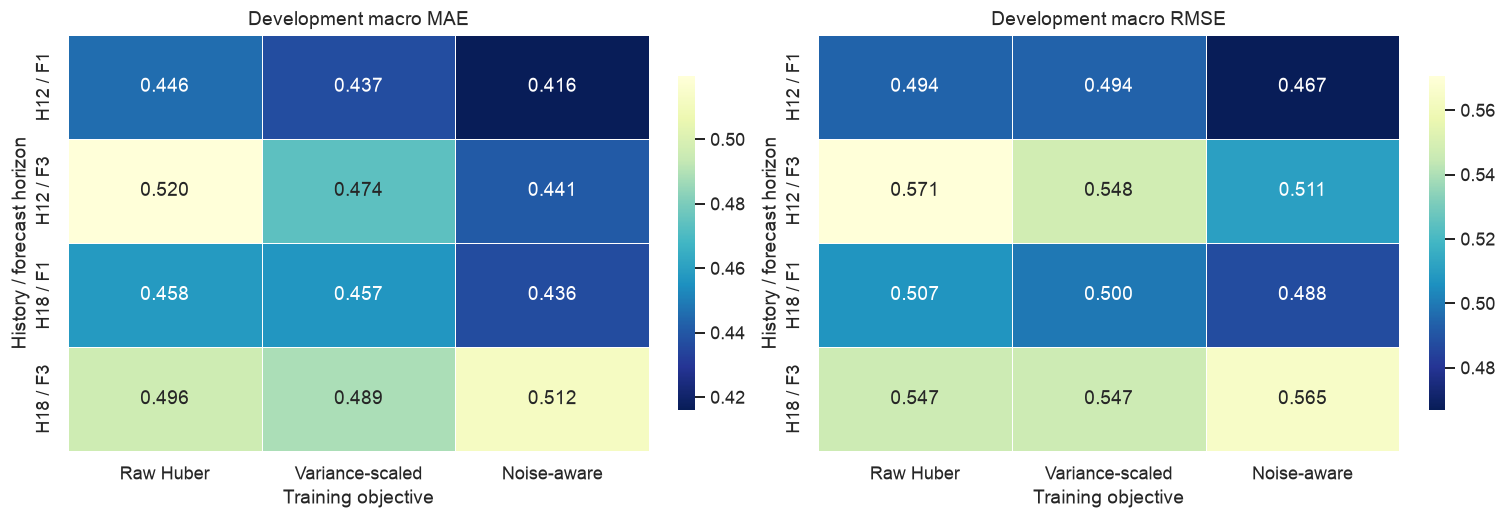

,history,horizon,loss,macro_observed_mae,macro_observed_rmse
0,12,1,noise,0.4162,0.4670
1,18,1,noise,0.4364,0.4876
2,12,1,variance,0.4369,0.4938
3,12,3,noise,0.4410,0.5107
4,12,1,raw,0.4459,0.4944
5,18,1,variance,0.4567,0.4997
6,18,1,raw,0.4578,0.5071
7,12,3,variance,0.4736,0.5481
8,18,3,variance,0.4886,0.5465
9,18,3,raw,0.4960,0.5467


**Selection result.** The lowest development macro MAE is **0.4162** (RMSE **0.4670**) for history **12**, horizon **1**, and **Noise-aware**. This identifies the development-preferred configuration; it does not establish independent test performance.

In [3]:
tab = summary.copy()
tab['objective'] = tab.loss.map(LOSS_NAMES)
tab['setting'] = tab.apply(lambda x:f"H{x.history} / F{x.horizon}", axis=1)
fig, ax = plt.subplots(1,2,figsize=(13,4.4),constrained_layout=True)
for a,metric,title in zip(ax,['macro_observed_mae','macro_observed_rmse'],['MAE','RMSE']):
    pv=tab.pivot(index='setting',columns='objective',values=metric).reindex(index=['H12 / F1','H12 / F3','H18 / F1','H18 / F3'],columns=list(LOSS_NAMES.values()))
    sns.heatmap(pv,annot=True,fmt='.3f',cmap='YlGnBu_r',linewidths=.5,ax=a,cbar_kws={'shrink':.8})
    a.set(title=f'Development macro {title}',xlabel='Training objective',ylabel='History / forecast horizon')
plt.show()
ranked=summary.sort_values('macro_observed_mae')
display(ranked[['history','horizon','loss','macro_observed_mae','macro_observed_rmse']].reset_index(drop=True).round(4))
win=ranked.iloc[0]
display(Markdown(f"**Selection result.** The lowest development macro MAE is **{win.macro_observed_mae:.4f}** (RMSE **{win.macro_observed_rmse:.4f}**) for history **{int(win.history)}**, horizon **{int(win.horizon)}**, and **{LOSS_NAMES[win.loss]}**. This identifies the development-preferred configuration; it does not establish independent test performance."))

In [4]:
# Quantitative interpretation of the history–horizon benchmark.
base=summary[(summary.history==12)&(summary.horizon==1)].set_index('loss')
raw=float(base.loc['raw','macro_observed_mae']); noise=float(base.loc['noise','macro_observed_mae'])
wins=summary.loc[summary.groupby(['history','horizon'])['macro_observed_mae'].idxmin()]
noise_wins=int((wins.loss=='noise').sum())
display(Markdown(f"**Interpretation.** At the one-step horizon with 12 observations of history, noise-aware Huber achieved a development macro MAE of {noise:.4f}, compared with {raw:.4f} for raw Huber, a {(raw-noise)/raw*100:.1f}% reduction. Noise-aware Huber had the lowest MAE in {noise_wins} of four history–horizon settings. The improvement is therefore configuration-dependent, not a universal ranking of training objectives. These development results were used for configuration selection and should not be interpreted as independent test estimates."))

**Interpretation.** At the one-step horizon with 12 observations of history, noise-aware Huber achieved a development macro MAE of 0.4162, compared with 0.4459 for raw Huber, a 6.7% reduction. Noise-aware Huber had the lowest MAE in 3 of four history–horizon settings. The improvement is therefore configuration-dependent, not a universal ranking of training objectives. These development results were used for configuration selection and should not be interpreted as independent test estimates.

In [5]:
best_by_window=summary.loc[summary.groupby(['history','horizon'])['macro_observed_mae'].idxmin()].sort_values(['history','horizon'])
noise_wins=(best_by_window.loss=='noise').sum()
short=summary[summary.horizon==1].macro_observed_mae.mean(); long=summary[summary.horizon==3].macro_observed_mae.mean()
display(Markdown(f"**Interpretation.** Noise-aware Huber gives the lowest macro MAE in {noise_wins} of four history–horizon settings. The lowest error is {win.macro_observed_mae:.4f} at H{int(win.history)}/F{int(win.horizon)}; the corresponding RMSE is {win.macro_observed_rmse:.4f}. Across all objectives and histories, mean macro MAE is {short:.4f} at one step and {long:.4f} at three steps. These comparisons identify a preferred development configuration but do not establish that the differences are statistically significant."))

**Interpretation.** Noise-aware Huber gives the lowest macro MAE in 3 of four history–horizon settings. The lowest error is 0.4162 at H12/F1; the corresponding RMSE is 0.4670. Across all objectives and histories, mean macro MAE is 0.4417 at one step and 0.4885 at three steps. These comparisons identify a preferred development configuration but do not establish that the differences are statistically significant.

## 3. Sensitivity to history length and forecast horizon

The paired lines below isolate how each objective responds to changing the forecast lead and history window. This is more informative than assuming that additional history always improves accuracy: longer sequences can introduce older observations without improving predictability.

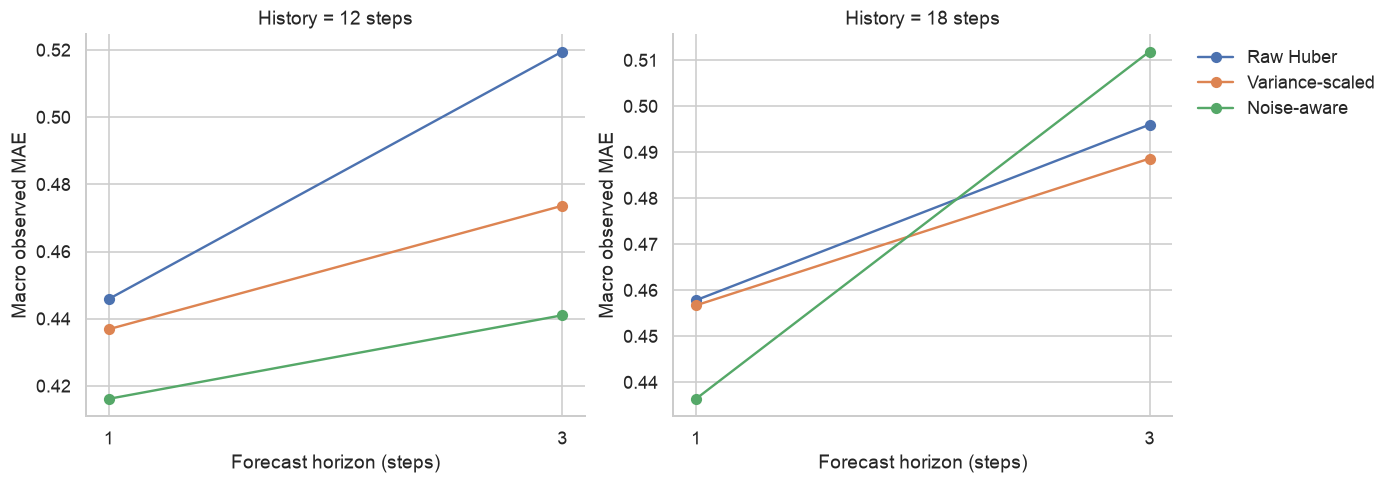

Noise-aware H12: horizon 1 MAE 0.4162; horizon 3 MAE 0.4410
Noise-aware H18: horizon 1 MAE 0.4364; horizon 3 MAE 0.5119


In [6]:
fig, axes=plt.subplots(1,2,figsize=(12,4.1),constrained_layout=True)
for a,h in zip(axes,[12,18]):
    d=summary[summary.history==h]
    for loss in ['raw','variance','noise']:
        q=d[d.loss==loss].sort_values('horizon')
        a.plot(q.horizon,q.macro_observed_mae,marker='o',label=LOSS_NAMES[loss])
    a.set(title=f'History = {h} steps',xlabel='Forecast horizon (steps)',ylabel='Macro observed MAE',xticks=[1,3])
axes[1].legend(frameon=False,bbox_to_anchor=(1.02,1),loc='upper left')
plt.show()
for h in [12,18]:
    d=summary[(summary.history==h)&(summary.loss=='noise')].set_index('horizon')
    print(f'Noise-aware H{h}: horizon 1 MAE {d.loc[1,"macro_observed_mae"]:.4f}; horizon 3 MAE {d.loc[3,"macro_observed_mae"]:.4f}')

In [7]:
# Interpret lead-time sensitivity and history effects from the plotted values.
lines=[]
for loss in ['raw','variance','noise']:
    d=summary[summary.loss==loss].set_index(['history','horizon'])
    delta=float(d.loc[(12,3),'macro_observed_mae']-d.loc[(12,1),'macro_observed_mae'])
    hdelta=float(d.loc[(18,1),'macro_observed_mae']-d.loc[(12,1),'macro_observed_mae'])
    lines.append(f"{LOSS_NAMES[loss]}: horizon 1→3 changes MAE by {delta:+.4f} at history 12; history 12→18 changes MAE by {hdelta:+.4f} at horizon 1")
display(Markdown('**Interpretation.** ' + '; '.join(lines) + '. These comparisons indicate how the measured error changes when one dimension is varied while the other is held fixed. They do not isolate a physical cause for the change.'))

**Interpretation.** Raw Huber: horizon 1→3 changes MAE by +0.0737 at history 12; history 12→18 changes MAE by +0.0120 at horizon 1; Variance-scaled: horizon 1→3 changes MAE by +0.0368 at history 12; history 12→18 changes MAE by +0.0198 at horizon 1; Noise-aware: horizon 1→3 changes MAE by +0.0249 at history 12; history 12→18 changes MAE by +0.0202 at horizon 1. These comparisons indicate how the measured error changes when one dimension is varied while the other is held fixed. They do not isolate a physical cause for the change.

In [8]:
d12=summary[summary.history==12].set_index(['horizon','loss']);d18=summary[summary.history==18].set_index(['horizon','loss'])
changes=[(h,l,float(summary.query('history==@h and horizon==3 and loss==@l').macro_observed_mae.iloc[0]-summary.query('history==@h and horizon==1 and loss==@l').macro_observed_mae.iloc[0])) for h in (12,18) for l in ('raw','variance','noise')]
more=sum(delta>0 for _,_,delta in changes)
display(Markdown(f"**Interpretation.** Increasing the forecast horizon from one to three steps raises macro MAE in {more} of six matched history–objective comparisons. For noise-aware Huber with 12-step history, MAE rises from {d12.loc[(1,'noise'),'macro_observed_mae']:.4f} to {d12.loc[(3,'noise'),'macro_observed_mae']:.4f}. A longer history is not uniformly beneficial: at one-step horizon, all three objectives have lower macro MAE with 12 rather than 18 input steps. The evidence supports empirical window selection for these experimental runs, not a general optimum for all operating conditions."))

**Interpretation.** Increasing the forecast horizon from one to three steps raises macro MAE in 6 of six matched history–objective comparisons. For noise-aware Huber with 12-step history, MAE rises from 0.4162 to 0.4410. A longer history is not uniformly beneficial: at one-step horizon, all three objectives have lower macro MAE with 12 rather than 18 input steps. The evidence supports empirical window selection for these experimental runs, not a general optimum for all operating conditions.

### Consistency of the three training objectives across held-out experiments
The aggregate ranking can conceal objectives that perform well on only a subset of runs. The following comparison restricts all objectives to identical measured targets.

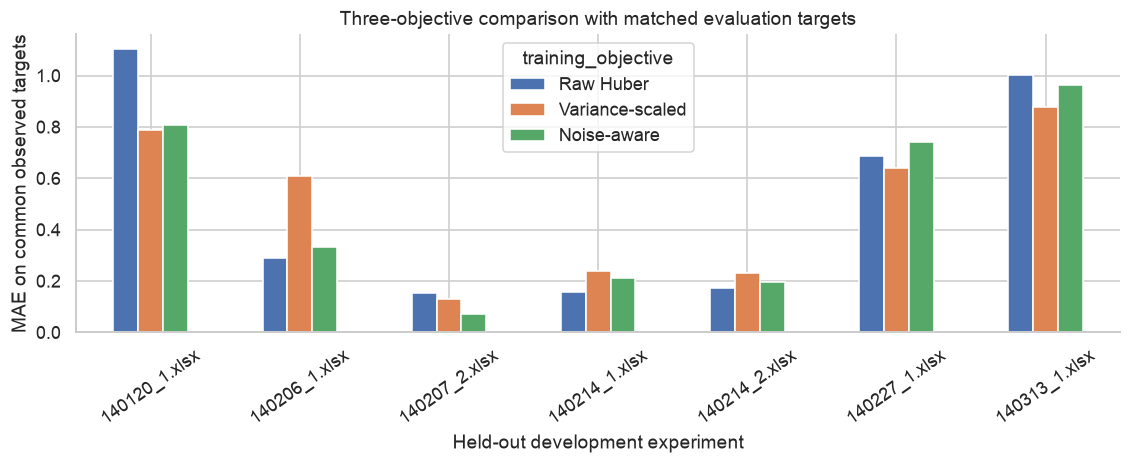

**Interpretation.** On 579 common development targets, noise-aware Huber has lower per-experiment MAE than raw Huber in 3 of 7 held-out runs. The mean experiment-level difference (noise − raw) is -0.0346, with a range of -0.2966 to +0.0560. This paired analysis tests consistency across experiments and avoids confounding by different target availability. It does not imply statistical significance with only seven experiments.

In [9]:
## Paired loss-objective robustness across development experiments
# Each comparison uses the same observed experiment/target-row/location keys.
sub=pred[(pred.history==12)&(pred.horizon==1)&(pred.input_mode==selected['mode'])].copy()
for col in ['observed','valid']:
    sub[col]=sub[col].astype(str).str.lower().isin(['true','1'])
sub=sub[sub.observed & sub.valid & sub.location.isin(['L2','L3','L4','L5','L6'])]
keys=['experiment','target_row','location']
wide=sub.pivot_table(index=keys,columns='training_objective',values=['y_pred','y_true'],aggfunc='first')
# Use a single common target value; assert objective-specific labels are consistent.
truth=wide['y_true']
assert (truth.max(axis=1)-truth.min(axis=1)).dropna().abs().max()<1e-8
common=wide['y_pred'][['raw','variance','noise']].dropna()
y=truth.loc[common.index,'raw']
loss_error=(common.sub(y,axis=0)).abs()
per_run=loss_error.groupby(level='experiment').mean()
fig,ax=plt.subplots(figsize=(10,4.2))
(per_run[['raw','variance','noise']].rename(columns=LOSS_NAMES)).plot(kind='bar',ax=ax)
ax.set(xlabel='Held-out development experiment',ylabel='MAE on common observed targets',title='Three-objective comparison with matched evaluation targets')
ax.tick_params(axis='x',rotation=35);plt.tight_layout();plt.show()
diff=per_run['noise']-per_run['raw']; wins=int((diff<0).sum())
display(Markdown(f"**Interpretation.** On {len(common)} common development targets, noise-aware Huber has lower per-experiment MAE than raw Huber in {wins} of {len(diff)} held-out runs. The mean experiment-level difference (noise − raw) is {diff.mean():+.4f}, with a range of {diff.min():+.4f} to {diff.max():+.4f}. This paired analysis tests consistency across experiments and avoids confounding by different target availability. It does not imply statistical significance with only seven experiments."))

## 4. Early stopping and optimization stability

Inner-fold validation determines the stopping epoch without directly selecting on the outer held-out experiment. The plots aggregate the *validation* learning trajectories across inner folds for the selected history and horizon. Fold trajectories have different lengths due to early stopping; later epochs therefore represent fewer surviving folds and should not be interpreted as a fixed cohort. The distribution of selected epochs provides a complementary view of training stability.

Available inner splits: <StringArray>
['train', 'inner_validation']
Length: 2, dtype: str


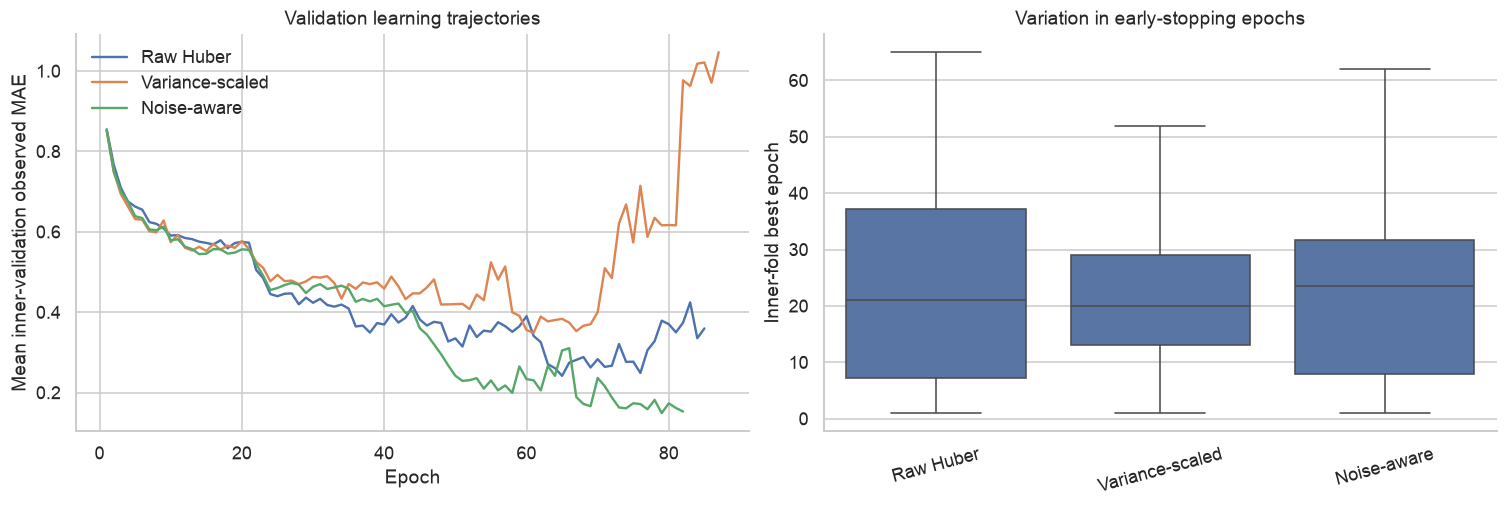

Saved selected final training duration: 43 epochs
Stop reasons: {'patience': 126}


In [10]:
chosen=summary[(summary.history==selected['history'])&(summary.horizon==selected['horizon'])]
ids=dict(zip(chosen.loss,chosen.config_id))
sub=inner[(inner.config_id.isin(ids.values())) & (inner.split.astype(str).str.lower().str.contains('val'))].copy()
print('Available inner splits:',inner.split.unique())
fig,axes=plt.subplots(1,2,figsize=(13,4.3),constrained_layout=True)
for loss,cid in ids.items():
    d=sub[sub.config_id==cid]
    if len(d):
        # Average within epoch over inner-validation runs; missing late epochs are not imputed.
        curve=d.groupby('epoch').agg(mae=('observed_mae','mean'),n=('observed_mae','count')).reset_index()
        axes[0].plot(curve.epoch,curve.mae,label=LOSS_NAMES[loss])
axes[0].set(xlabel='Epoch',ylabel='Mean inner-validation observed MAE',title='Validation learning trajectories')
axes[0].legend(frameon=False)
es=stops[stops.config_id.isin(ids.values())].copy()
es['objective']=es.config_id.map({v:LOSS_NAMES[k] for k,v in ids.items()})
sns.boxplot(data=es,x='objective',y='best_epoch',ax=axes[1],showfliers=False)
axes[1].set(xlabel='',ylabel='Inner-fold best epoch',title='Variation in early-stopping epochs')
axes[1].tick_params(axis='x',rotation=15)
plt.show()
print('Saved selected final training duration:',selected['epoch'],'epochs')
print('Stop reasons:',es.stop_reason.value_counts().to_dict())

In [11]:
# The plotted means can have different numbers of contributing validation folds at later epochs.
if len(es):
    epoch_stats=es.groupby('objective').best_epoch.agg(['median','min','max','count']).round(1)
    display(epoch_stats)
    span=epoch_stats['max']-epoch_stats['min']
    display(Markdown('**Interpretation.** The inner-fold best epochs range from '+', '.join(f"{k}: {int(epoch_stats.loc[k,'min'])}–{int(epoch_stats.loc[k,'max'])}" for k in epoch_stats.index)+f". The final training duration ({selected['epoch']} epochs) was fixed from development validation, not chosen from test performance. Mean validation curves at late epochs can represent fewer folds because early-stopped runs contribute no subsequent epochs; they should not be read as a common uninterrupted training trajectory."))

,median,min,max,count
objective,,,,
Noise-aware,23.5,1,62,42
Raw Huber,21.0,1,65,42
Variance-scaled,20.0,1,67,42


**Interpretation.** The inner-fold best epochs range from Noise-aware: 1–62, Raw Huber: 1–65, Variance-scaled: 1–67. The final training duration (43 epochs) was fixed from development validation, not chosen from test performance. Mean validation curves at late epochs can represent fewer folds because early-stopped runs contribute no subsequent epochs; they should not be read as a common uninterrupted training trajectory.

## 5. Cross-experiment generalization

Macro averages can obscure substantial differences between held-out experiments. This comparison uses the saved **outer-fold** observed-target metrics for the selected configuration and reports variability rather than only the overall mean. The distribution of errors across experiments is a direct test of transfer across distinct operating runs.

Fold metric locations: ['L2', 'L3', 'L4', 'L5', 'L6']


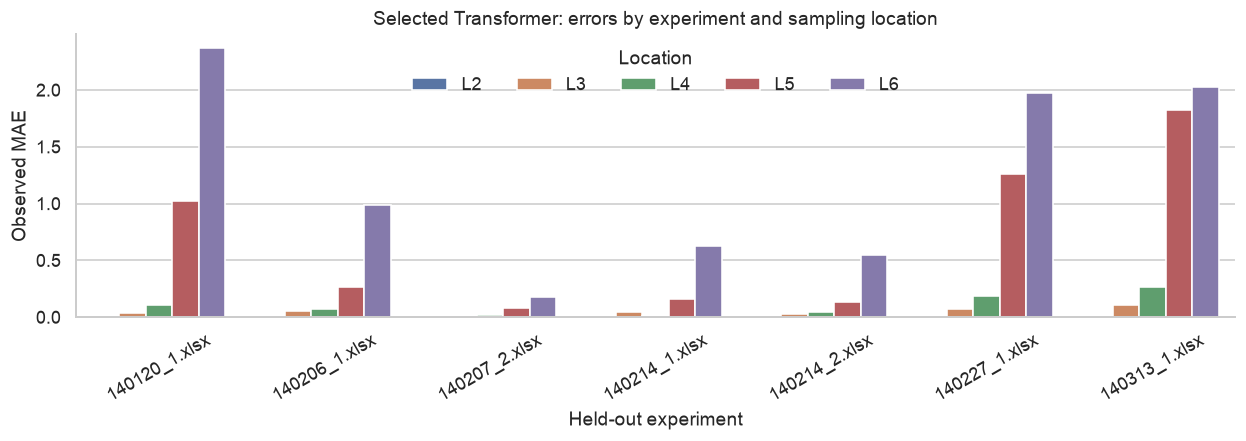

In [12]:
cid=summary[(summary.history==selected['history'])&(summary.horizon==selected['horizon'])&(summary.loss==selected['loss'])].iloc[0].config_id
q=folds[(folds.config_id==cid)&(folds.method=='transformer')&folds.location.isin(['L2','L3','L4','L5','L6'])].copy()
print('Fold metric locations:',sorted(folds.location.astype(str).unique())[:15])
if len(q):
    fig,ax=plt.subplots(figsize=(11,4))
    sns.barplot(data=q,x='held',y='mae',hue='location',ax=ax,errorbar=None)
    ax.set(xlabel='Held-out experiment',ylabel='Observed MAE',title='Selected Transformer: errors by experiment and sampling location')
    ax.tick_params(axis='x',rotation=30)
    ax.legend(title='Location',ncol=5,frameon=False)
    plt.tight_layout();plt.show()
else:
    print('Per-location outer-fold summary unavailable; use the prediction-level analysis below.')

In [13]:
if len(q):
    v=q.groupby('held').apply(lambda g: pd.Series({'mean_location_mae':g.mae.mean(),'n_locations':len(g)}),include_groups=False).sort_values('mean_location_mae')
    display(Markdown(f"**Interpretation.** For the selected configuration, the mean of available location-level MAEs ranges from {v.iloc[0].mean_location_mae:.4f} in {v.index[0]} to {v.iloc[-1].mean_location_mae:.4f} in {v.index[-1]}. This is a descriptive mean across reported locations, not a pooled observation-weighted MAE. The between-experiment variation motivates testing operating-state and concentration-distribution differences in the separate root-cause analysis."))

**Interpretation.** For the selected configuration, the mean of available location-level MAEs ranges from 0.0584 in 140207_2.xlsx to 0.8444 in 140313_1.xlsx. This is a descriptive mean across reported locations, not a pooled observation-weighted MAE. The between-experiment variation motivates testing operating-state and concentration-distribution differences in the separate root-cause analysis.

,experiment,n,MAE
2,140207_2.xlsx,32,0.0726
4,140214_2.xlsx,32,0.1950
3,140214_1.xlsx,46,0.2109
1,140206_1.xlsx,32,0.3334
5,140227_1.xlsx,170,0.7433
0,140120_1.xlsx,87,0.8083
6,140313_1.xlsx,180,0.9640


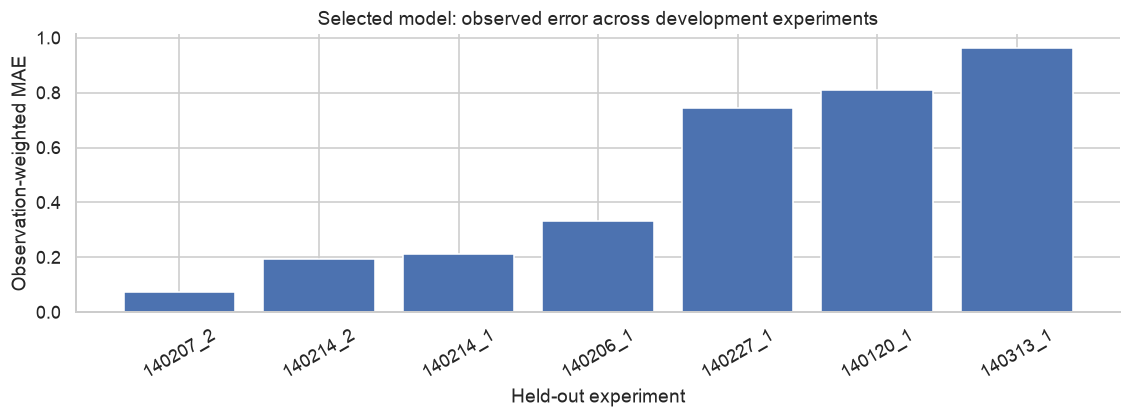

**Finding.** Observation-level MAE ranges from 0.0726 in 140207_2.xlsx (n=32) to 0.9640 in 140313_1.xlsx (n=180), a difference of 0.8914. **Interpretation.** Error varies across independently held-out experimental runs; these differences may reflect both concentration distributions and process conditions. **Implication.** A single pooled score does not adequately characterize cross-experiment performance. The run-level values here are observation-weighted and are not substituted for the separately reported configuration-selection macro statistic.

In [14]:
# Observation-level held-out errors, using the same eligible target definition as the main evaluation.
selected_predictions = pred[(pred.history==selected['history']) & (pred.horizon==selected['horizon']) & (pred.training_objective==selected['loss']) & (pred.input_mode==selected['mode'])].copy()
for flag in ['observed','valid']:
    selected_predictions[flag]=selected_predictions[flag].astype(str).str.lower().isin(['true','1'])
selected_predictions=selected_predictions[selected_predictions.observed & selected_predictions.valid & selected_predictions.location.isin(['L2','L3','L4','L5','L6']) & selected_predictions.y_true.notna() & selected_predictions.y_pred.notna()].copy()
assert selected_predictions.groupby(['experiment','target_row','location']).size().max()==1
selected_predictions['absolute_error']=(selected_predictions.y_pred-selected_predictions.y_true).abs()
run_errors=selected_predictions.groupby('experiment').agg(n=('absolute_error','size'),MAE=('absolute_error','mean')).reset_index().sort_values('MAE')
display(run_errors.round(4))
fig,ax=plt.subplots(figsize=(10,3.8))
ax.bar(run_errors.experiment.str.replace('.xlsx','',regex=False),run_errors.MAE)
ax.set(xlabel='Held-out experiment',ylabel='Observation-weighted MAE',title='Selected model: observed error across development experiments')
ax.tick_params(axis='x',rotation=30);plt.tight_layout();plt.show()
lowest=run_errors.iloc[0];highest=run_errors.iloc[-1]
display(Markdown(f"**Finding.** Observation-level MAE ranges from {lowest.MAE:.4f} in {lowest.experiment} (n={int(lowest.n)}) to {highest.MAE:.4f} in {highest.experiment} (n={int(highest.n)}), a difference of {highest.MAE-lowest.MAE:.4f}. **Interpretation.** Error varies across independently held-out experimental runs; these differences may reflect both concentration distributions and process conditions. **Implication.** A single pooled score does not adequately characterize cross-experiment performance. The run-level values here are observation-weighted and are not substituted for the separately reported configuration-selection macro statistic.") )

## 6. Observed-only evaluation and paired persistence benchmark

Persistence carries forward the last available measured concentration at each location. It is a relevant benchmark for slowly varying concentration series. The head-to-head comparison uses identical observed L2–L6 target records with valid forecasts from both methods.

**Transformer (paired)** denotes the original Transformer predictions restricted to records where persistence is available; it is not a separately trained model. The unqualified Transformer score includes all eligible observed targets and may therefore use a different sample count. Only paired scores support a direct performance comparison.

,Model,n,MAE,RMSE,Bias
0,Transformer,579,0.6894,1.1825,-0.0914
1,Transformer (paired),549,0.6663,1.1547,-0.0945
2,Persistence (paired),549,0.2363,0.5179,-0.0226


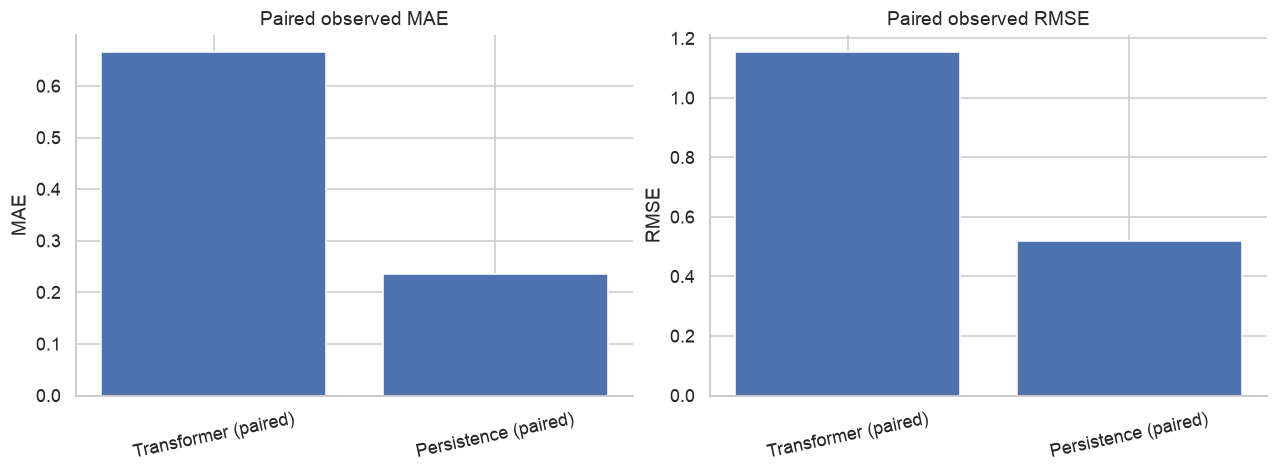

Mean absolute-error advantage (positive = Transformer better): -0.43
Fraction of paired records where Transformer is better: 0.259


In [15]:
def eligible_observed(frame):
    d=frame.copy()
    for col in ['observed','valid','persistence_available']:
        d[col]=d[col].astype(str).str.lower().isin(['true','1'])
    d=d[d.location.isin(['L2','L3','L4','L5','L6']) & d.observed & d.valid].copy()
    d=d[np.isfinite(pd.to_numeric(d.y_true,errors='coerce')) & np.isfinite(pd.to_numeric(d.y_pred,errors='coerce'))].copy()
    d['transformer_error']=d.y_pred-d.y_true
    d['persistence_error']=d.persistence_pred-d.y_true
    paired=d[d.persistence_available & np.isfinite(pd.to_numeric(d.persistence_pred,errors='coerce'))].copy()
    return d,paired

p,paired=eligible_observed(pred[(pred.history==selected['history'])&(pred.horizon==selected['horizon'])&(pred.training_objective==selected['loss'])&(pred.input_mode==selected['mode'])])
assert len(p)>0 and len(paired)>0
assert not paired[['y_true','y_pred','persistence_pred']].isna().any().any()
def metrics(df,error):
    e=df[error].to_numpy(float)
    return {'n':len(e),'MAE':np.abs(e).mean(),'RMSE':np.sqrt(np.square(e).mean()),'Bias':e.mean()}
report=pd.DataFrame([{'Model':'Transformer',**metrics(p,'transformer_error')},
                     {'Model':'Transformer (paired)',**metrics(paired,'transformer_error')},
                     {'Model':'Persistence (paired)',**metrics(paired,'persistence_error')}])
display(report.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for a,metric in zip(axes,['MAE','RMSE']):
    a.bar(report[report.Model.str.contains('paired')]['Model'],report[report.Model.str.contains('paired')][metric])
    a.set(title=f'Paired observed {metric}',xlabel='',ylabel=metric)
    a.tick_params(axis='x',rotation=12)
plt.show()
paired['abs_error_advantage']=np.abs(paired.persistence_error)-np.abs(paired.transformer_error)
print('Mean absolute-error advantage (positive = Transformer better):',round(paired.abs_error_advantage.mean(),4))
print('Fraction of paired records where Transformer is better:',round((paired.abs_error_advantage>0).mean(),3))

In [16]:
if len(paired):
    mt=metrics(paired,'transformer_error');mp=metrics(paired,'persistence_error')
    display(Markdown(f"**Interpretation.** On {len(paired)} matched development observations, Transformer MAE was {mt['MAE']:.4f} and persistence MAE was {mp['MAE']:.4f} ({(mt['MAE']/mp['MAE']-1)*100:+.1f}% relative difference). The paired restriction makes this comparison fair with respect to target availability. It does not remove differences in model complexity or establish the cause of the performance gap."))

**Interpretation.** On 549 matched development observations, Transformer MAE was 0.6663 and persistence MAE was 0.2363 (+182.0% relative difference). The paired restriction makes this comparison fair with respect to target availability. It does not remove differences in model complexity or establish the cause of the performance gap.

## 7. Location-specific accuracy and systematic bias

Concentration magnitudes differ considerably along the absorber. We therefore report both absolute errors and signed bias by location. The latter distinguishes systematic overprediction from underprediction. L1 is omitted because its raw analyzer measurements are not reliable independent targets.

,Location,n,MAE,RMSE,Bias
0,L2,117,0.0073,0.0127,-0.0001
1,L3,117,0.0690,0.0919,-0.0004
2,L4,80,0.1642,0.1965,0.0040
3,L5,117,1.0883,1.3574,-0.0491
4,L6,148,1.6873,1.9965,-0.3204


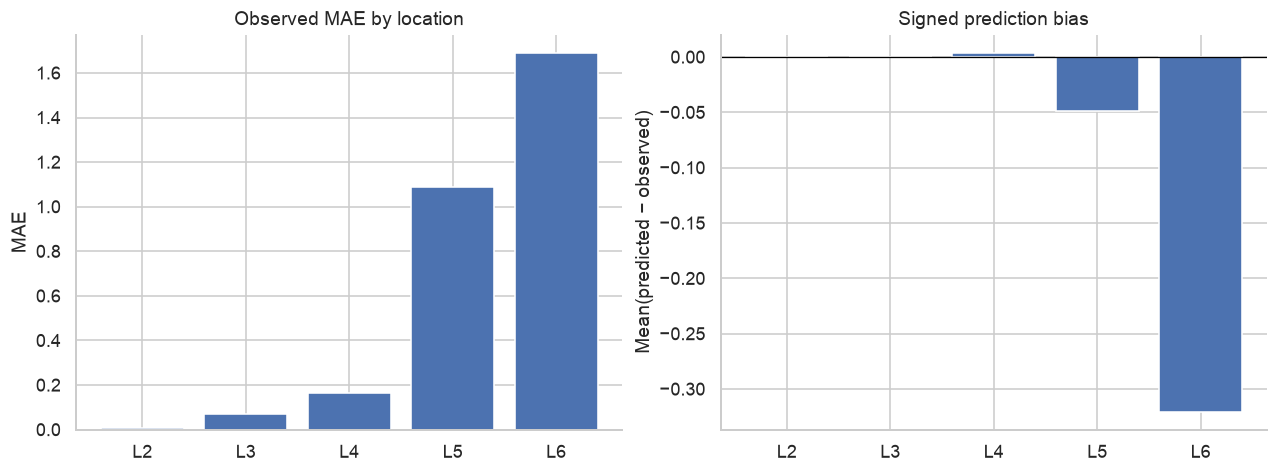

In [17]:
rows=[]
for loc,g in p.groupby('location'):
    rows.append({'Location':loc,**metrics(g,'transformer_error')})
loc_metrics=pd.DataFrame(rows).sort_values('Location')
display(loc_metrics.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
axes[0].bar(loc_metrics.Location,loc_metrics.MAE)
axes[1].bar(loc_metrics.Location,loc_metrics.Bias)
axes[0].set(title='Observed MAE by location',ylabel='MAE')
axes[1].axhline(0,color='black',linewidth=.8)
axes[1].set(title='Signed prediction bias',ylabel='Mean(predicted − observed)')
plt.show()

In [18]:
if len(loc_metrics):
    s=loc_metrics.sort_values('MAE')
    display(Markdown(f"**Interpretation.** Development observed-target MAE ranges from {s.iloc[0].MAE:.4f} at {s.iloc[0].Location} to {s.iloc[-1].MAE:.4f} at {s.iloc[-1].Location}. Because CO₂ concentration scales differ by location, this ranking describes absolute error rather than scale-independent forecasting difficulty. Signed bias should be considered separately from MAE to distinguish persistent offsets from variable errors."))

**Interpretation.** Development observed-target MAE ranges from 0.0073 at L2 to 1.6873 at L6. Because CO₂ concentration scales differ by location, this ranking describes absolute error rather than scale-independent forecasting difficulty. Signed bias should be considered separately from MAE to distinguish persistent offsets from variable errors.

## 8. Prediction agreement and illustrative time trajectories

A prediction–observation plot tests agreement over the full observed range. Temporal plots show how the model behaves along individual experiment sequences. These are descriptive views of the selected development configuration; they are not independent final-test figures. Each point corresponds to a target observation at a forecast horizon, not necessarily a continuously observed concentration profile.

/Users/niharikadeshpande/Downloads/co2_transformer_submission/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


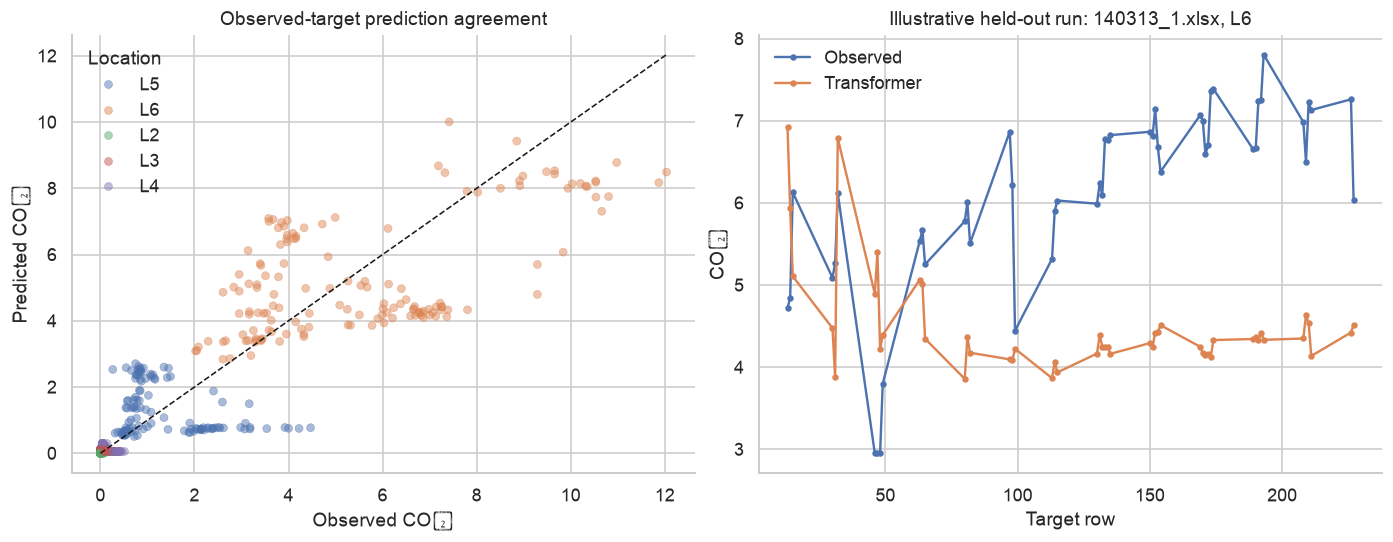

In [19]:
fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
sns.scatterplot(data=p,x='y_true',y='y_pred',hue='location',alpha=.48,s=25,ax=axes[0],edgecolor=None)
lo=min(p.y_true.min(),p.y_pred.min());hi=max(p.y_true.max(),p.y_pred.max())
axes[0].plot([lo,hi],[lo,hi],'k--',lw=1)
axes[0].set(xlabel='Observed CO₂',ylabel='Predicted CO₂',title='Observed-target prediction agreement')
axes[0].legend(title='Location',frameon=False)
# Representative held-out run chosen deterministically by highest available observed count.
run=p.groupby('experiment').size().idxmax()
loc='L6' if (p[(p.experiment==run)&(p.location=='L6')].shape[0]>2) else p[p.experiment==run].location.value_counts().idxmax()
t=p[(p.experiment==run)&(p.location==loc)].sort_values('target_row')
axes[1].plot(t.target_row,t.y_true,'o-',label='Observed',markersize=3)
axes[1].plot(t.target_row,t.y_pred,'o-',label='Transformer',markersize=3)
axes[1].set(xlabel='Target row',ylabel='CO₂',title=f'Illustrative held-out run: {run}, {loc}')
axes[1].legend(frameon=False)
plt.show()

In [20]:
# Quantify range compression and association instead of merely defining the 1:1 line.
rows=[]
for loc,g in p.groupby('location'):
    if len(g)>2:
        rows.append({'location':loc,'n':len(g),'observed_sd':g.y_true.std(),'predicted_sd':g.y_pred.std(),'bias':(g.y_pred-g.y_true).mean(),'correlation':g[['y_true','y_pred']].corr().iloc[0,1]})
cal=pd.DataFrame(rows);display(cal.round(4))
if len(cal):
    cal['SD ratio']=cal.predicted_sd/cal.observed_sd.replace(0,np.nan)
    display(cal[['location','n','SD ratio','bias','correlation']].round(4))
    compressed=cal[cal['SD ratio']<1].location.tolist()
    offset=cal.iloc[cal.bias.abs().argmax()]
    display(Markdown(f"**Interpretation.** Predicted variability is lower than observed variability at {len(compressed)} of {len(cal)} locations ({', '.join(compressed) if compressed else 'none'}), as assessed by the within-location standard-deviation ratio. The largest absolute signed offset occurs at {offset.location} (bias {offset.bias:+.4f}); this is distinct from variability attenuation. Correlation measures co-variation, not agreement, and location-specific statistics avoid spurious association caused by pooling different concentration scales."))

,location,n,observed_sd,predicted_sd,bias,correlation
0,L2,117,0.0120,0.0019,-0.0001,-0.3733
1,L3,117,0.0774,0.0354,-0.0004,-0.2328
2,L4,80,0.1329,0.0956,0.0040,-0.4824
3,L5,117,0.9611,0.7327,-0.0491,-0.2808
4,L6,148,2.4659,1.7316,-0.3204,0.6053


,location,n,SD ratio,bias,correlation
0,L2,117,0.1552,-0.0001,-0.3733
1,L3,117,0.4576,-0.0004,-0.2328
2,L4,80,0.7197,0.0040,-0.4824
3,L5,117,0.7623,-0.0491,-0.2808
4,L6,148,0.7022,-0.3204,0.6053


**Interpretation.** Predicted variability is lower than observed variability at 5 of 5 locations (L2, L3, L4, L5, L6), as assessed by the within-location standard-deviation ratio. The largest absolute signed offset occurs at L6 (bias -0.3204); this is distinct from variability attenuation. Correlation measures co-variation, not agreement, and location-specific statistics avoid spurious association caused by pooling different concentration scales.

## 8A. Paired skill by held-out experiment and observation age

The first plot reports paired MAE differences (Transformer minus persistence) for each development experiment; negative values favor the Transformer. The second examines absolute error against the recorded logarithmic measurement-age encoding. This motivates a more detailed examination of measurement availability in Notebook 3.

,Experiment,n,Transformer MAE,Persistence MAE,MAE difference
0,140120_1,83,0.7015,0.4388,0.2626
1,140206_1,28,0.3171,0.3423,-0.0252
2,140207_2,28,0.0580,0.1364,-0.0785
3,140214_1,41,0.1530,0.1500,0.0030
4,140214_2,28,0.1531,0.1796,-0.0265
5,140227_1,165,0.7152,0.1031,0.6121
6,140313_1,176,0.9573,0.2938,0.6636


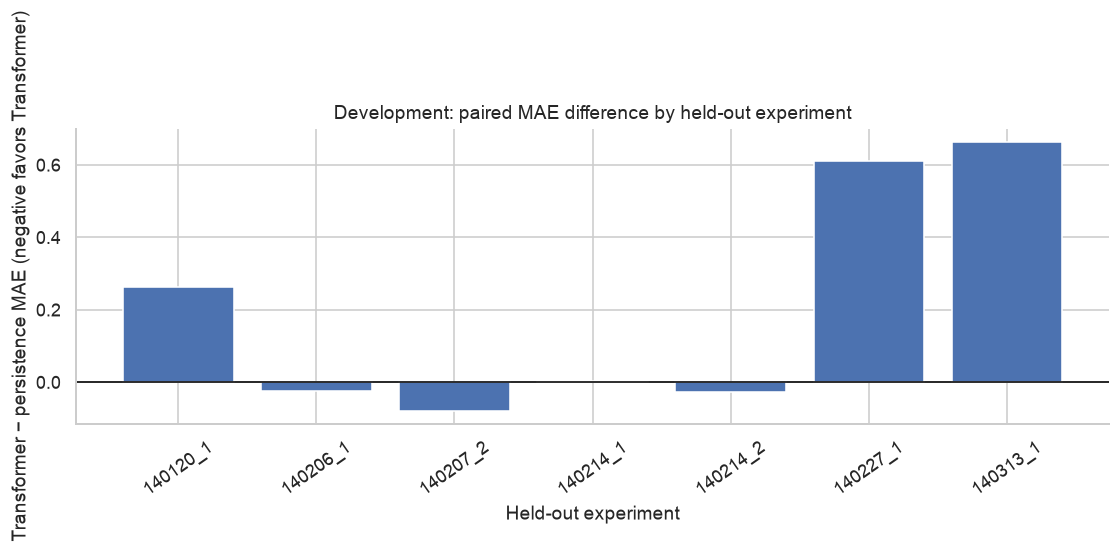

,Age bin,n,transformer_mae,persistence_mae
0,"(2.638, 2.708]",179,0.6125,0.2670
1,"(2.708, 2.773]",178,0.5881,0.2232
2,"(2.773, 2.833]",133,0.6449,0.1984
3,"(2.833, 2.996]",59,1.1138,0.2680


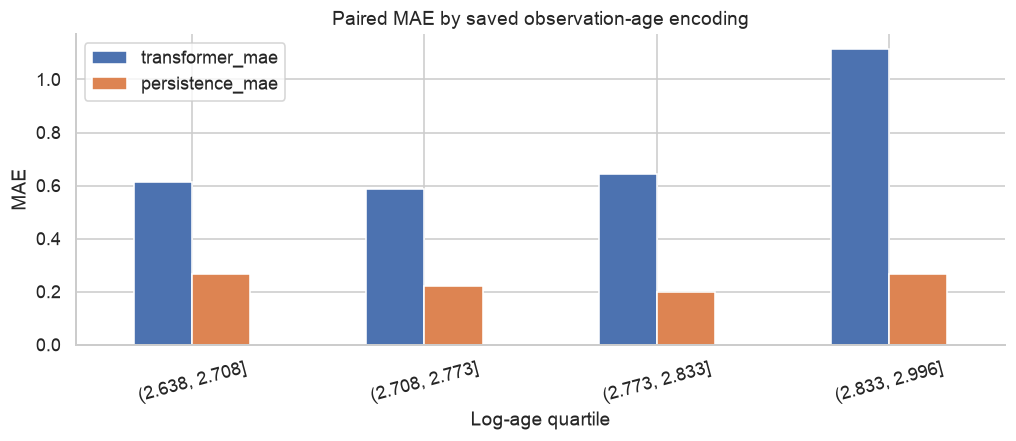

In [21]:
by_fold=[]
for experiment,g in paired.groupby('experiment'):
    by_fold.append({'Experiment':experiment.replace('.xlsx',''),'n':len(g),
                    'Transformer MAE':np.abs(g.transformer_error).mean(),
                    'Persistence MAE':np.abs(g.persistence_error).mean()})
by_fold=pd.DataFrame(by_fold).sort_values('Experiment')
by_fold['MAE difference']=by_fold['Transformer MAE']-by_fold['Persistence MAE']
display(by_fold.round(4))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(by_fold.Experiment,by_fold['MAE difference'])
ax.axhline(0,color='black',linewidth=1)
ax.set(title='Development: paired MAE difference by held-out experiment',ylabel='Transformer − persistence MAE (negative favors Transformer)',xlabel='Held-out experiment')
ax.tick_params(axis='x',rotation=35);plt.tight_layout();plt.show()
if 'measurement_age_log_rows' in paired:
    a=paired.copy();a['Age bin']=pd.qcut(a.measurement_age_log_rows, q=4,duplicates='drop')
    age=a.groupby('Age bin',observed=True).agg(n=('transformer_error','size'),
      transformer_mae=('transformer_error',lambda x:np.abs(x).mean()),
      persistence_mae=('persistence_error',lambda x:np.abs(x).mean())).reset_index()
    age['Age bin']=age['Age bin'].astype(str)
    display(age.round(4))
    ax=age.plot(x='Age bin',y=['transformer_mae','persistence_mae'],kind='bar',figsize=(9,4),rot=15)
    ax.set(title='Paired MAE by saved observation-age encoding',ylabel='MAE',xlabel='Log-age quartile');plt.tight_layout();plt.show()


In [22]:
if len(by_fold):
    w=int((by_fold['MAE difference']<0).sum());worst=by_fold.loc[by_fold['MAE difference'].idxmax()];best=by_fold.loc[by_fold['MAE difference'].idxmin()]
    display(Markdown(f"**Interpretation.** The Transformer has lower paired MAE than persistence in {w} of {len(by_fold)} held-out development experiments. The largest Transformer disadvantage is {worst['MAE difference']:+.4f} in {worst.Experiment} (n={int(worst.n)}), whereas the most favorable difference is {best['MAE difference']:+.4f} in {best.Experiment} (n={int(best.n)}). This heterogeneity is more informative than a pooled score alone; small experiment-level sample sizes limit precision."))

**Interpretation.** The Transformer has lower paired MAE than persistence in 3 of 7 held-out development experiments. The largest Transformer disadvantage is +0.6636 in 140313_1 (n=176), whereas the most favorable difference is -0.0785 in 140207_2 (n=28). This heterogeneity is more informative than a pooled score alone; small experiment-level sample sizes limit precision.

## 9. Development findings and model-selection decision

The selected configuration minimizes macro observed MAE across the seven development experiments, rather than error on a single run. The benchmark establishes sensitivity to temporal window and training objective; learning curves characterize optimization; paired persistence comparisons assess incremental forecasting skill; and location-specific residuals identify systematic error patterns. These development findings motivate, but do not replace, the reserved-test evaluation.

In [23]:
best=ranked.iloc[0]
if len(paired):
    a=metrics(paired,'transformer_error');b=metrics(paired,'persistence_error')
    comparison=(f"On {len(paired):,} matched observed predictions, the selected Transformer has MAE {a['MAE']:.4f} "
                f"versus {b['MAE']:.4f} for persistence. " + ('It improves on persistence for this paired sample.' if a['MAE']<b['MAE'] else 'Persistence remains stronger on this paired sample.'))
else: comparison='A paired persistence comparison could not be computed from the available saved records.'
display(Markdown(f"**Results synthesis.** Development selection favors H{int(best.history)}/F{int(best.horizon)} with {LOSS_NAMES[best.loss]} (macro MAE {best.macro_observed_mae:.4f}). {comparison}"))

**Results synthesis.** Development selection favors H12/F1 with Noise-aware (macro MAE 0.4162). On 549 matched observed predictions, the selected Transformer has MAE 0.6663 versus 0.2363 for persistence. Persistence remains stronger on this paired sample.

## 10. Independent held-out test: `140207_1.xlsx`

The selected configuration—history 12, horizon 1, noise-aware Huber, 43 training epochs—was fixed before evaluation on the reserved experiment. The following tables and figures use saved final-test predictions and metrics. Results are reported for all eligible observed Transformer targets and separately for the matched Transformer–persistence subset.

,Subset,n,MAE,RMSE,Bias
0,Transformer: all observed,88,0.14457,0.27752,0.10044
1,Transformer: paired,83,0.11668,0.22410,0.06991
2,Persistence: paired,83,0.07643,0.15870,-0.02757


,Location,n,MAE,RMSE,Bias
0,L2,18,0.00450,0.00450,0.00450
1,L3,18,0.02503,0.02974,0.00859
2,L4,13,0.02197,0.02992,-0.01292
3,L5,18,0.08402,0.09933,0.00421
4,L6,21,0.49487,0.55942,0.41408


/Users/niharikadeshpande/Downloads/co2_transformer_submission/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


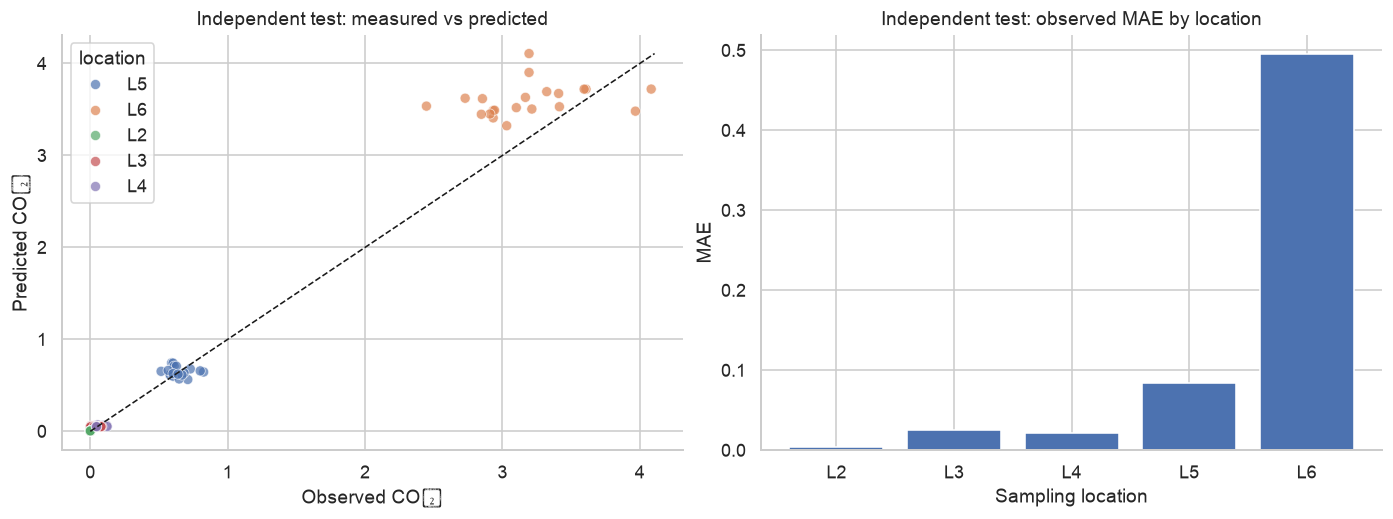

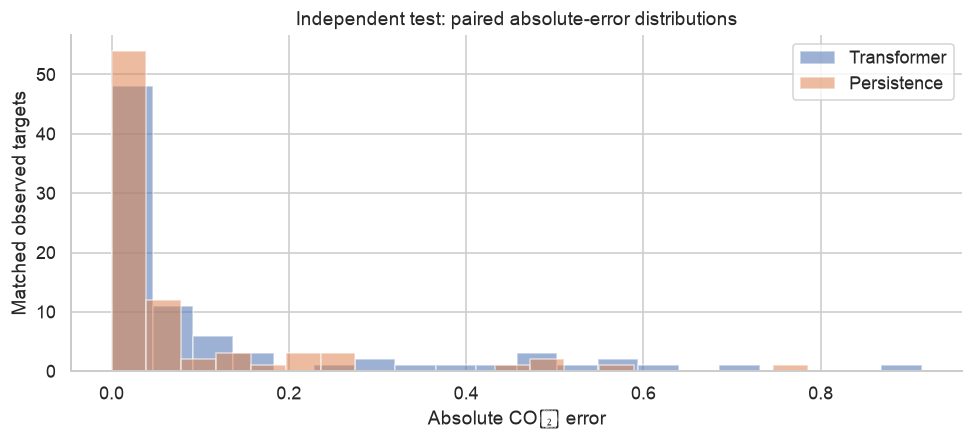

Matched test sample size: 83 of 88 observed L2–L6 targets


In [24]:
test_file=ROOT/'results'/'final_test'/'final_predictions.csv'
if not test_file.exists():
    raise FileNotFoundError(f'Independent final test predictions required: {test_file}')
test_all=pd.read_csv(test_file)
for c in ['observed','valid','persistence_available']:
    test_all[c]=test_all[c].astype(str).str.lower().isin(['true','1'])
assert test_all.experiment.nunique()==1 and test_all.experiment.iloc[0]=='140207_1.xlsx'
assert set(test_all.training_objective)=={selected['loss']}
test,test_paired=eligible_observed(test_all)
assert len(test)>0 and len(test_paired)>0
final_report=pd.DataFrame([{'Subset':'Transformer: all observed',**metrics(test,'transformer_error')},
    {'Subset':'Transformer: paired',**metrics(test_paired,'transformer_error')},
    {'Subset':'Persistence: paired',**metrics(test_paired,'persistence_error')}])
display(final_report.round(5))
loc_test=[]
for loc,g in test.groupby('location'):
    loc_test.append({'Location':loc,**metrics(g,'transformer_error')})
loc_test=pd.DataFrame(loc_test)
display(loc_test.round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4.4),constrained_layout=True)
sns.scatterplot(data=test,x='y_true',y='y_pred',hue='location',s=40,alpha=.7,ax=axes[0])
lim=max(test.y_true.max(),test.y_pred.max());axes[0].plot([0,lim],[0,lim],'k--',lw=1)
axes[0].set(title='Independent test: measured vs predicted',xlabel='Observed CO₂',ylabel='Predicted CO₂')
axes[1].bar(loc_test.Location,loc_test.MAE)
axes[1].set(title='Independent test: observed MAE by location',xlabel='Sampling location',ylabel='MAE')
plt.show()
fig,ax=plt.subplots(figsize=(10,3.8))
for model,errs in [('Transformer',test_paired.transformer_error),('Persistence',test_paired.persistence_error)]:
    ax.hist(np.abs(errs),bins=20,alpha=.55,label=model)
ax.set(title='Independent test: paired absolute-error distributions',xlabel='Absolute CO₂ error',ylabel='Matched observed targets');ax.legend();plt.show()
print('Matched test sample size:',len(test_paired),'of',len(test),'observed L2–L6 targets')


In [25]:
mt=metrics(test_paired,'transformer_error');mp=metrics(test_paired,'persistence_error')
l6=loc_test[loc_test.Location=='L6'].iloc[0]
display(Markdown(f"**Interpretation.** The independent test contains {len(test)} eligible observed targets, of which {len(test_paired)} permit a paired persistence comparison. On matched targets, Transformer MAE is {mt['MAE']:.4f} versus {mp['MAE']:.4f} for persistence, a {(mt['MAE']/mp['MAE']-1)*100:.1f}% higher error. L6 has the largest test absolute error (MAE {l6.MAE:.4f}) and a positive mean residual of {l6.Bias:+.4f}; this identifies systematic overprediction in this test run. The aggregate difference should not be interpreted as uniform across sampling locations."))

**Interpretation.** The independent test contains 88 eligible observed targets, of which 83 permit a paired persistence comparison. On matched targets, Transformer MAE is 0.1167 versus 0.0764 for persistence, a 52.7% higher error. L6 has the largest test absolute error (MAE 0.4949) and a positive mean residual of +0.4141; this identifies systematic overprediction in this test run. The aggregate difference should not be interpreted as uniform across sampling locations.

### Independent-test prediction agreement and time-ordered behavior
Location-specific agreement and temporal traces help distinguish a persistent prediction offset from an inability to represent measured variation.

/Users/niharikadeshpande/Downloads/co2_transformer_submission/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


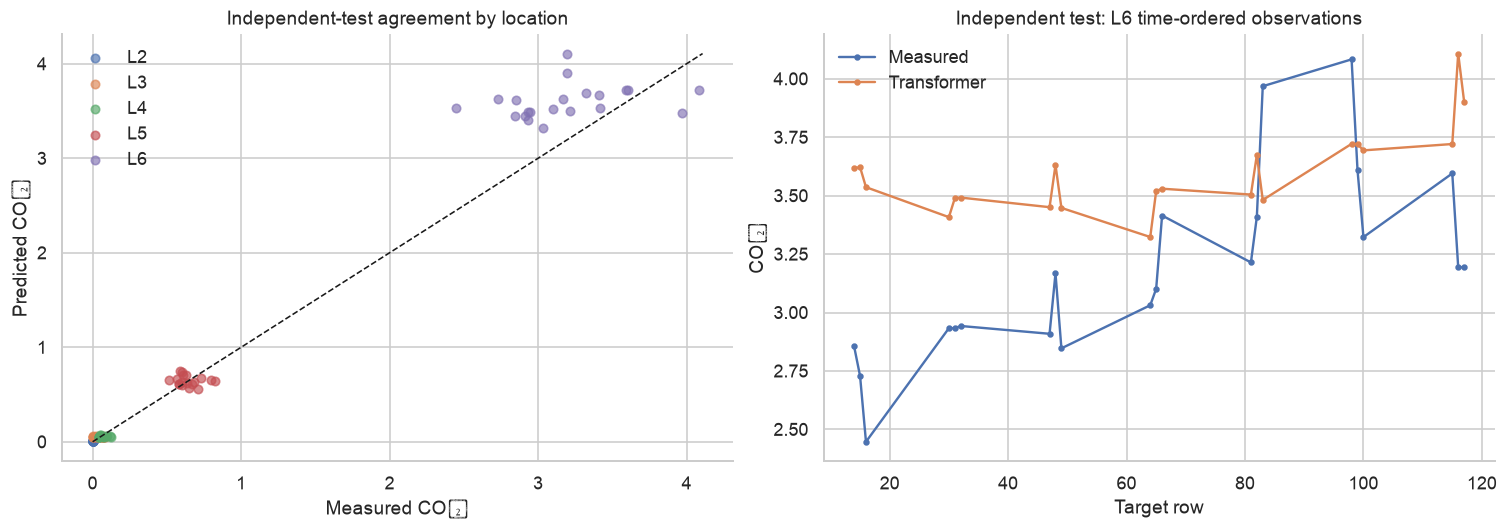

,Location,n,Observed SD,Predicted SD,Bias
0,L2,18,0.0000,0.0001,0.0045
1,L3,18,0.0294,0.0033,0.0086
2,L4,13,0.0284,0.0068,-0.0129
3,L5,18,0.0805,0.0527,0.0042
4,L6,21,0.3975,0.1776,0.4141


**Interpretation.** L6 exhibits a mean prediction offset of +0.4141 across 21 measured targets. Its observed standard deviation is 0.3975, compared with 0.1776 for the predictions. Of these L6 targets, 19 have positive residuals (90.5%). The median residual is +0.4639; the first and second halves have mean residuals +0.6224 and +0.2247, respectively. These time-ordered summaries distinguish a broadly persistent offset from an error concentrated in one part of the run. The small number of measured targets and sequential dependence preclude treating individual points as independent experimental replicates.

In [26]:
## Independent-test calibration and temporal behavior
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for loc,g in test.groupby('location'):
    axes[0].scatter(g.y_true,g.y_pred,label=loc,alpha=.65,s=28)
lo=min(test.y_true.min(),test.y_pred.min());hi=max(test.y_true.max(),test.y_pred.max())
axes[0].plot([lo,hi],[lo,hi],'k--',lw=1)
axes[0].set(xlabel='Measured CO₂',ylabel='Predicted CO₂',title='Independent-test agreement by location');axes[0].legend(frameon=False)
l6t=test[test.location=='L6'].sort_values('target_row')
axes[1].plot(l6t.target_row,l6t.y_true,'o-',ms=3,label='Measured')
axes[1].plot(l6t.target_row,l6t.y_pred,'o-',ms=3,label='Transformer')
axes[1].set(xlabel='Target row',ylabel='CO₂',title='Independent test: L6 time-ordered observations');axes[1].legend(frameon=False)
plt.show()
caltest=[]
for loc,g in test.groupby('location'):
    caltest.append({'Location':loc,'n':len(g),'Observed SD':g.y_true.std(),'Predicted SD':g.y_pred.std(),'Bias':g.transformer_error.mean()})
caltest=pd.DataFrame(caltest);display(caltest.round(4))
display(Markdown(f"**Interpretation.** L6 exhibits a mean prediction offset of {l6t.transformer_error.mean():+.4f} across {len(l6t)} measured targets. Its observed standard deviation is {l6t.y_true.std():.4f}, compared with {l6t.y_pred.std():.4f} for the predictions. Of these L6 targets, {(l6t.transformer_error>0).sum()} have positive residuals ({(l6t.transformer_error>0).mean()*100:.1f}%). The median residual is {l6t.transformer_error.median():+.4f}; the first and second halves have mean residuals {l6t.transformer_error.iloc[:len(l6t)//2].mean():+.4f} and {l6t.transformer_error.iloc[len(l6t)//2:].mean():+.4f}, respectively. These time-ordered summaries distinguish a broadly persistent offset from an error concentrated in one part of the run. The small number of measured targets and sequential dependence preclude treating individual points as independent experimental replicates."))

### Independent-test temporal changes at L6

The following diagnostic compares changes between successive **measured L6 targets**, not changes between consecutive 43-second process records. Consecutive L6 measurements are separated by several process records; the increment statistics therefore describe the observed L6 sampling cadence and should not be interpreted as one-step concentration increments. The number of increments is one fewer than the number of L6 measurements.

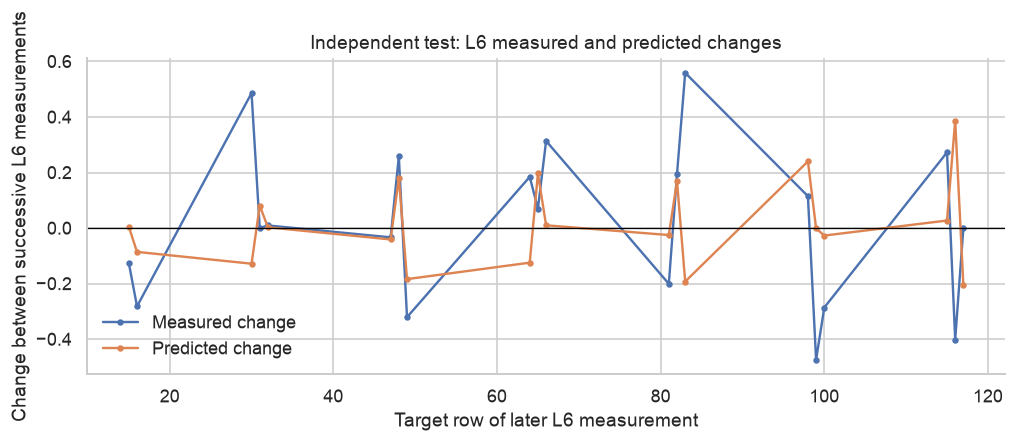

,Pairs,Measured change SD,Predicted change SD,Change correlation,Change MAE
0,20,0.2884,0.1566,-0.1448,0.252


**Finding.** Across 20 successive L6 measurement pairs, measured-change SD is 0.2884 and predicted-change SD is 0.1566 (ratio 0.543); change correlation is -0.145 and change MAE is 0.2520. **Interpretation.** These statistics distinguish responsiveness to changes from the previously reported mean offset. **Implication.** Any difference in change variability or agreement warrants investigation of the causal historical inputs and concentration dynamics; the small, serially dependent sample does not support a causal conclusion.

In [27]:
l6t=test[test.location=='L6'].sort_values('target_row').copy()
assert l6t.target_row.is_unique
l6t['measured_change']=l6t.y_true.diff()
l6t['predicted_change']=l6t.y_pred.diff()
inc=l6t.dropna(subset=['measured_change','predicted_change']).copy()
assert len(inc)>=3
inc_corr=inc.measured_change.corr(inc.predicted_change) if inc.measured_change.std()>0 and inc.predicted_change.std()>0 else np.nan
change_sd_obs=inc.measured_change.std(ddof=1);change_sd_pred=inc.predicted_change.std(ddof=1)
change_mae=np.abs(inc.predicted_change-inc.measured_change).mean()
fig,ax=plt.subplots(figsize=(9,3.8))
ax.plot(inc.target_row,inc.measured_change,'o-',ms=3,label='Measured change')
ax.plot(inc.target_row,inc.predicted_change,'o-',ms=3,label='Predicted change')
ax.axhline(0,color='black',lw=.8)
ax.set(xlabel='Target row of later L6 measurement',ylabel='Change between successive L6 measurements',title='Independent test: L6 measured and predicted changes')
ax.legend(frameon=False);plt.tight_layout();plt.show()
display(pd.DataFrame([{'Pairs':len(inc),'Measured change SD':change_sd_obs,'Predicted change SD':change_sd_pred,'Change correlation':inc_corr,'Change MAE':change_mae}]).round(4))
ratio=change_sd_pred/change_sd_obs if change_sd_obs>0 else np.nan
correlation_text=f'{inc_corr:+.3f}' if np.isfinite(inc_corr) else 'undefined (zero variation)'
display(Markdown(f"**Finding.** Across {len(inc)} successive L6 measurement pairs, measured-change SD is {change_sd_obs:.4f} and predicted-change SD is {change_sd_pred:.4f} (ratio {ratio:.3f}); change correlation is {correlation_text} and change MAE is {change_mae:.4f}. **Interpretation.** These statistics distinguish responsiveness to changes from the previously reported mean offset. **Implication.** Any difference in change variability or agreement warrants investigation of the causal historical inputs and concentration dynamics; the small, serially dependent sample does not support a causal conclusion."))

### Independent-test error structure: signed offset and variable residuals

At each location, $\mathrm{MSE}=\mathrm{Bias}^2+\mathrm{Var}(e)$ when residual variance uses denominator $n$. This separates mean offset from residual dispersion. The predicted-to-observed standard-deviation ratio provides a complementary measure of how much concentration variability is represented.

,Location,n,RMSE,Bias,Bias² / MSE,Residual SD,Predicted / observed SD
0,L2,18,0.0045,0.0045,0.9996,0.0001,NaN
1,L3,18,0.0297,0.0086,0.0835,0.0285,0.1140
2,L4,13,0.0299,-0.0129,0.1865,0.0270,0.2402
3,L5,18,0.0993,0.0042,0.0018,0.0992,0.6545
4,L6,21,0.5594,0.4141,0.5479,0.3761,0.4469


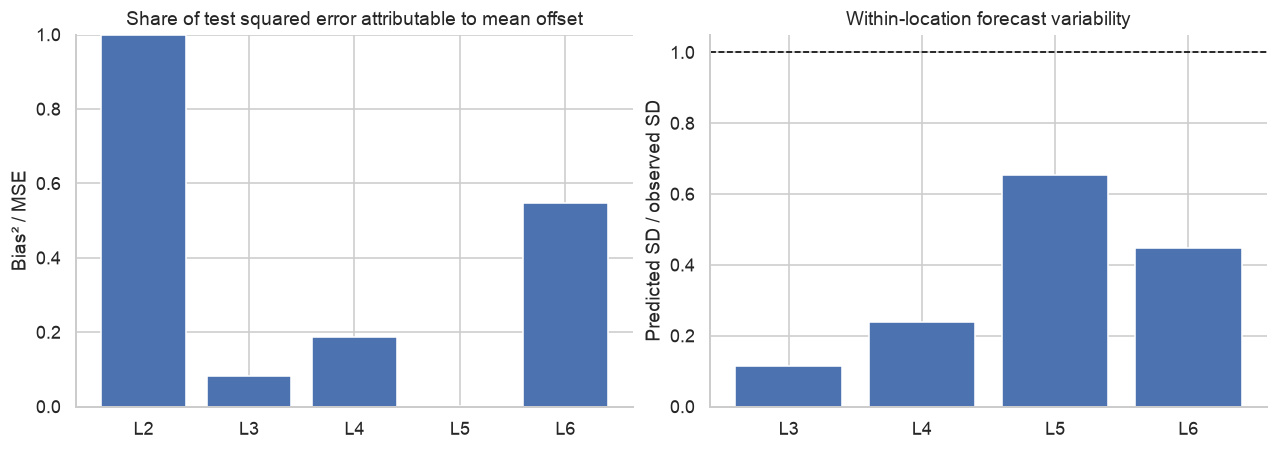

**Interpretation.** At L6, the squared mean residual accounts for 54.8% of mean squared error; the remaining 45.2% reflects residual dispersion around that offset. The largest bias contribution occurs at L2 (100.0%). Predicted concentration variability is smaller than observed variability at 4 of 5 locations (L3, L4, L5, L6). A high bias fraction identifies a potentially correctable systematic offset but does not establish why it occurs; a low variability ratio indicates attenuation of measured fluctuations, not necessarily poor calibration of the mean.

In [28]:
error_structure=[]
for loc,g in test.groupby('location'):
    e=g.transformer_error.to_numpy(float)
    mse=np.mean(e**2); bias=np.mean(e)
    obs_sd=g.y_true.std(ddof=0); pred_sd=g.y_pred.std(ddof=0)
    error_structure.append({'Location':loc,'n':len(g),'RMSE':np.sqrt(mse),
       'Bias':bias,'Bias² / MSE':bias**2/mse if mse>0 else np.nan,
       'Residual SD':np.std(e,ddof=0),'Predicted / observed SD':pred_sd/obs_sd if obs_sd>0 else np.nan})
structure=pd.DataFrame(error_structure).sort_values('Location')
display(structure.round(4))
fig,axes=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
axes[0].bar(structure.Location,structure['Bias² / MSE'])
axes[0].set(title='Share of test squared error attributable to mean offset',ylabel='Bias² / MSE',ylim=(0,1))
axes[1].bar(structure.Location,structure['Predicted / observed SD'])
axes[1].axhline(1,color='black',linestyle='--',lw=1)
axes[1].set(title='Within-location forecast variability',ylabel='Predicted SD / observed SD')
plt.show()
l6s=structure[structure.Location=='L6'].iloc[0]
maxbias=structure.loc[structure['Bias² / MSE'].idxmax()]
under=structure[structure['Predicted / observed SD']<1].Location.tolist()
display(Markdown(f"**Interpretation.** At L6, the squared mean residual accounts for {100*l6s['Bias² / MSE']:.1f}% of mean squared error; the remaining {100*(1-l6s['Bias² / MSE']):.1f}% reflects residual dispersion around that offset. The largest bias contribution occurs at {maxbias.Location} ({100*maxbias['Bias² / MSE']:.1f}%). Predicted concentration variability is smaller than observed variability at {len(under)} of {len(structure)} locations ({', '.join(under) if under else 'none'}). A high bias fraction identifies a potentially correctable systematic offset but does not establish why it occurs; a low variability ratio indicates attenuation of measured fluctuations, not necessarily poor calibration of the mean."))

### Metric definitions

For observed L2–L6 targets, residual $e=\hat C-C$. **MAE** is $n^{-1}\sum|e|$, **RMSE** is $\sqrt{n^{-1}\sum e^2}$, and **bias** is $n^{-1}\sum e$ (positive indicates overprediction). **Macro** scores average experiment-level metrics equally; **pooled** scores combine eligible forecast records. **Paired** comparisons evaluate both methods on the same records.

## 11. Independent-test error decomposition

The aggregate test MAE combines locations with substantially different concentration magnitudes. The following analysis separates **relative scale** (MAE divided by the observed interquartile range, when nonzero) from **baseline skill** (paired Transformer minus persistence MAE). The normalization uses only observed test values for descriptive reporting; it does not alter training or model selection. The time-ordered plot uses saved forecast-origin indices rather than assuming every target is sampled at every time step.

,Location,n,Observed IQR,Normalized MAE (MAE/IQR),Paired MAE difference,Paired n
0,L2,18,0.0000,NaN,0.0045,18
1,L3,18,0.0436,0.5737,0.0019,18
2,L4,13,0.0421,0.5217,-0.0031,13
3,L5,18,0.0840,1.0002,0.0178,16
4,L6,21,0.4764,1.0388,0.1657,18


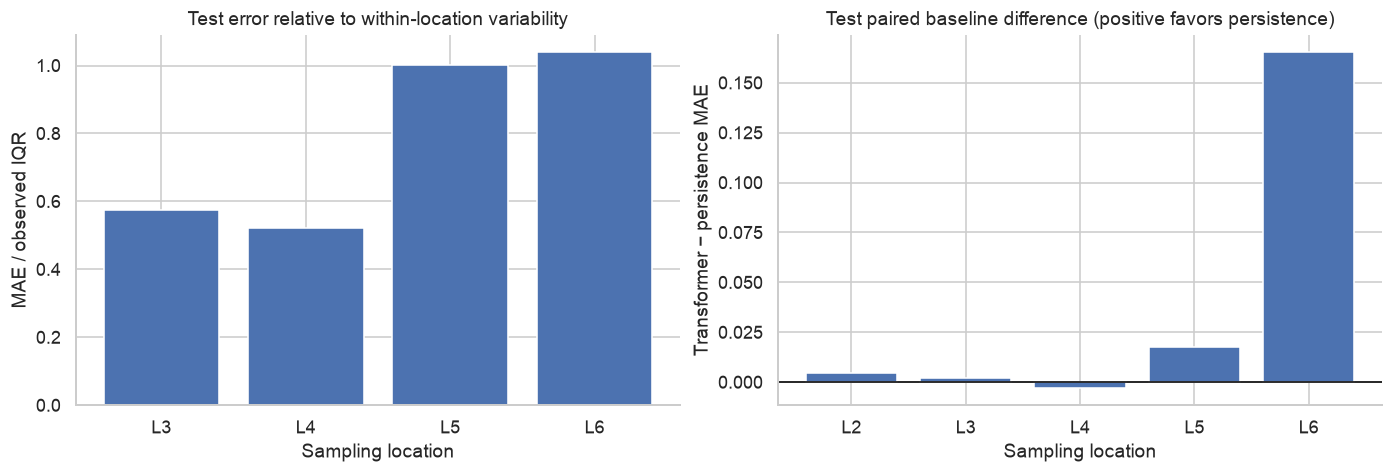

**Interpretation.** After dividing MAE by the observed within-location IQR, the largest relative error occurs at L6 (MAE/IQR 1.039). This measure can become unstable where observed concentrations vary very little; it is descriptive, not a replacement for the primary MAE. Positive paired differences identify locations where persistence has lower MAE on exactly matched targets.

In [29]:
test_by_loc=[]
for loc,g in test.groupby('location'):
    q75,q25=np.quantile(g.y_true,[.75,.25]);iqr=q75-q25
    gp=test_paired[test_paired.location==loc]
    test_by_loc.append({'Location':loc,'n':len(g),'Observed IQR':iqr,
        'Normalized MAE (MAE/IQR)':np.abs(g.transformer_error).mean()/iqr if iqr>1e-12 else np.nan,
        'Paired MAE difference':np.abs(gp.transformer_error).mean()-np.abs(gp.persistence_error).mean() if len(gp) else np.nan,
        'Paired n':len(gp)})
loc_diag=pd.DataFrame(test_by_loc)
display(loc_diag.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].bar(loc_diag.Location,loc_diag['Normalized MAE (MAE/IQR)']);axes[0].set(xlabel='Sampling location',ylabel='MAE / observed IQR',title='Test error relative to within-location variability')
axes[1].bar(loc_diag.Location,loc_diag['Paired MAE difference']);axes[1].axhline(0,color='black',lw=1);axes[1].set(xlabel='Sampling location',ylabel='Transformer − persistence MAE',title='Test paired baseline difference (positive favors persistence)')
plt.show()
valid_diag=loc_diag.dropna(subset=['Normalized MAE (MAE/IQR)'])
if len(valid_diag):
    w=valid_diag.loc[valid_diag['Normalized MAE (MAE/IQR)'].idxmax()]
    display(Markdown(f"**Interpretation.** After dividing MAE by the observed within-location IQR, the largest relative error occurs at {w.Location} (MAE/IQR {w['Normalized MAE (MAE/IQR)']:.3f}). This measure can become unstable where observed concentrations vary very little; it is descriptive, not a replacement for the primary MAE. Positive paired differences identify locations where persistence has lower MAE on exactly matched targets."))


In [30]:
# Interpret location-normalized error and matched baseline differences separately.
if len(loc_diag):
    pos=loc_diag.dropna(subset=['Paired MAE difference']).sort_values('Paired MAE difference',ascending=False)
    if len(pos):
        display(Markdown(f"**Interpretation.** The largest paired test disadvantage relative to persistence occurs at {pos.iloc[0].Location} (MAE difference {pos.iloc[0]['Paired MAE difference']:+.4f}, n={int(pos.iloc[0]['Paired n'])}). The MAE/IQR statistic assesses error relative to observed within-location spread, but can be unstable for nearly constant concentrations. Neither statistic alone demonstrates operating-regime shift; that requires explicit comparison of process-state distributions."))

**Interpretation.** The largest paired test disadvantage relative to persistence occurs at L6 (MAE difference +0.1657, n=18). The MAE/IQR statistic assesses error relative to observed within-location spread, but can be unstable for nearly constant concentrations. Neither statistic alone demonstrates operating-regime shift; that requires explicit comparison of process-state distributions.

### Principal evaluation findings

Twelve combinations of history length, forecast horizon, and training objective were evaluated across seven development experiments. The selected 12-step, one-step, noise-aware Huber configuration was tested on `140207_1.xlsx` without further tuning. **Across 83 matched test observations, Transformer MAE was 0.1167 versus 0.0764 for persistence; RMSE was 0.2241 versus 0.1587.** The Transformer did not outperform the measurement-based benchmark at the selected horizon.

Test errors varied by sampling location. L6 had the largest absolute error and a positive mean residual. The location-specific agreement, temporal-increment, and error-decomposition analyses characterize whether the discrepancy reflects a persistent offset, residual variability, or incomplete representation of measured changes. Development performance also varied by experiment and training objective, limiting the usefulness of a single aggregate score.

These findings establish specific questions for the accompanying root-cause analysis: whether forecast errors covary with operating-state distance, temporal concentration changes, or historical measurement age. The independent test contains only one experimental run; broader operating-condition generalization and real-time label availability remain unverified.